# Vasc compartment: scVI integration of clean data

In [1]:
import sys 
import os
from datetime import datetime

import pandas as pd
import numpy as np
import scanpy as sc
import anndata as ad
import scvi
import hdf5plugin

import matplotlib.pyplot as plt
import seaborn as sns

# Add repo path to sys path (allows to access scripts and metadata from repo)
repo_path = os.path.split(os.getcwd())[0]
sys.path.insert(1, repo_path) 
sys.path.insert(2, '/lustre/scratch126/cellgen/team205/lm25/thymus_projects/thymus_ageing_atlas/General_analysis/scripts')

import torch
torch.cuda.is_available()

%reload_ext autoreload
%autoreload 2

from scvi_wrapper2 import run_scvi

In [2]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all" # to show output from all the lines in a cells
pd.set_option('display.max_column',None) # display all the columns in pandas
pd.options.display.max_rows = 100
import matplotlib
from matplotlib import rcParams
rcParams['pdf.fonttype'] = 42
sc.settings.set_figure_params(dpi = 150, color_map = 'RdPu', dpi_save = 150, vector_friendly = True, format = 'pdf')

In [3]:
# Define plot and path dirs
plot_path = os.path.join(repo_path, 'plots')
data_path = os.path.join(repo_path, 'data')
model_path = os.path.join(repo_path, 'models')
general_data_path = '/lustre/scratch126/cellgen/team205/lm25/thymus_projects/thymus_ageing_atlas/General_analysis/data'

In [4]:
def regen_embed (adata, anno2show):
    sc.pp.neighbors(adata, use_rep = 'X_scVI')
    sc.tl.umap(adata, min_dist = 0.1, spread = 1)
    sc.pl.umap(adata, color = anno2show)
    return (adata)

def ctypist_anno(adata, model, col_name, mv = False, clusters = None):
    import celltypist
    predictions = celltypist.annotate(adata, model=model, majority_voting = mv, over_clustering = clusters)
    predictions.to_adata(prefix=f'ctypist_{col_name}_')
    if mv:
        sc.pl.umap(adata, color = f'ctypist_{col_name}_majority_voting', frameon = False)
    else:
        sc.pl.umap(adata, color = f'ctypist_{col_name}_predicted_labels', frameon = False)

def run_leiden(adata, resolutions, key_name,restrict_to = None, legend_loc = "on data", legend_fontsize = 4):
    for r in resolutions:
        if restrict_to:
            sc.tl.leiden(adata, restrict_to = restrict_to, resolution = r, key_added = f'{key_name}-leiden_r{str(r)}',
                        flavor="igraph", n_iterations=2)
        else:
            sc.tl.leiden(adata, resolution = r, key_added = f'{key_name}-leiden_r{str(r)}',
                        flavor="igraph", n_iterations=2)
    sc.pl.umap(adata, color = [f'{key_name}-leiden_r{str(r)}' for r in resolutions] , legend_loc = legend_loc, legend_fontsize = legend_fontsize)


In [5]:
def remove_small_samples(adata, sample_anno = 'sample', less_than=3):
    samples2remove = adata.obs[sample_anno].value_counts().loc[(adata.obs[sample_anno].value_counts()<less_than)].index.tolist()
    print(samples2remove)
    n_cells_orig = adata.shape[0]
    adata = adata[~adata.obs[sample_anno].isin(samples2remove),:].copy()
    n_cells = adata.shape[0]
    print(f'{str(n_cells_orig-n_cells)} cells were removed')
    return(adata)

In [6]:
general_mrkrs = ['PTPRC', 'CD3G', 
               'HOXA9', 
               'HES1', #DN
               'RORC', #DP
               'CCR9',
              'PDCD1', #CD8aa
              'CD8A', 'CD8B', 
              'CD4', 'CD40LG', 
              'CRTAM', 'ANXA1', #memory
             'FOXP3', 'DHRS3', 
               'TRDC', #gama-delta 
              'EOMES', 'KLRD1', # NK cells
              'TNFSF11', # ILC
              'CD19', 'VPREB1', # pre-pro B cells
              'IGHD', 'IGHA1', 'IGHG1', 
              'CLEC9A', 'CLEC10A', 
              'LAMP3', 
             'LILRA4','S100A9', 'C1QA', 'TPSB2', 'ITGA2B', 'GYPA', 
              'PDGFRA', 'COLEC11', 'FBN1', 
              'RGS5', 'CDH5', 
               'LYVE1', 'EPCAM', 'PSMB11', 'DLK2', 'KRT14', 
               'CCL19', 'AIRE', 'KRT1', 'POU2F3',
               'MYOD1', 'NEUROG1']

In [14]:
vasc_mrkrs_dict = {'pan-vasc': ['PECAM1', 'CDH5','VWF', "EGFL7","CLU"],
                   'large vassels': ['OGN', 'OMD', 'BGN', 'ELN','SULF1'],
                   'large_art_ec': ["BGN","OMD","OGN","EFEMP1"],
                    'art_ec_1': ["ELN","SULF1","COL8A1","ABI3BP","GUCY1A1","SSTR1"],
                    'art_ec_2': ["NEBL","NTRK2","ALPL"],
                  'arteria': ['GJA5', 'ARL15', 'PLLP', 'SERPINE2', 'HEY1', 'SEMA3G', 'DLL4', 'NEBL'],
                   
                  'capillary': ['RGCC', 'GPIHBP1', 'CA4', 'EFNB1', 'FCN3'],
                   'capillary-adipose': ['FABP4', 'FABP5', 'MEOX2', 'TCF15', 'CD36', 'LPL'],
                   'venous': ["ACKR1","NR2F2","PLVAP","POSTN","COL15A1",'SELE', 'C7'],
                    'ven_ec_1': ["POSTN","C7","SELP"],
    'ven_ec_2': ["SELE","ICAM4","CSF3","PCDH19"],
                   'lymphatic': ['PROX1', 'TFF3', 'CCL21']
                  }
vasc_mrkrs=[]
[vasc_mrkrs.extend(vasc_mrkrs_dict[key]) for key in vasc_mrkrs_dict.keys()]

[None, None, None, None, None, None, None, None, None, None, None, None]

vasc_mrkrs_dict = {'pan-vasc': ['PECAM1', 'CDH5','VWF'],
                  'arteria': ['CXCL12', 'SEMA3G', 'HEY1'],
                   'large vassels': ['SULF1', 'ELN'],
                  'capillary': ['RGCC', 'PLVAP'],
                   'prolif': ['MKI67'],
                   'venous': ['ACKR1', 'ICAM1', 'CCL2', 'SELE'],
                   'lymphatic': ['PROX1', 'TFF3', 'CCL21']
                  }

vasc_mrkrs=[]
[vasc_mrkrs.extend(vasc_mrkrs_dict[key]) for key in vasc_mrkrs_dict.keys()]

## Subset to Vasculature

In [15]:
# Load data
adata_stroma = ad.read_h5ad (f'/nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/data/objects/thyAgeing_scvi_v3_2024-11-05_tec-fb-vascSplit_v5_2layers_300epochs_2025-01-06.zarr')

stroma_obs = pd.read_csv(f'/nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/data/objects/thyAgeing_scvi_v3_2024-11-05_tec-fb-vascSplit_doubl_anno2_2025-01-07.csv', index_col = 0)

adata_stroma.obs[['stroma-anno2-coarse', 'stroma-anno2-granular', 'doublet', 'doublet_verbose']] = stroma_obs.reindex(adata_stroma.obs_names)[['stroma-anno2-coarse', 'stroma-anno2-granular', 'doublet', 'doublet_verbose']].copy()

/tmp/ipykernel_3208950/2605147994.py:4: DtypeWarning: Columns (5,6,7,8,9,14,15,17,20,21,34,35,36,45,46,47,48,49,50) have mixed types. Specify dtype option on import or set low_memory=False.
  stroma_obs = pd.read_csv(f'/nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/data/objects/thyAgeing_scvi_v3_2024-11-05_tec-fb-vascSplit_doubl_anno2_2025-01-07.csv', index_col = 0)


In [16]:
adata_stroma.obs['stroma-anno2-coarse'].value_counts()

stroma-anno2-coarse
TEC         90001
Fb          71301
EC          54352
SMC         14331
Pericyte    12655
doublet      7555
TEC-EMT      4490
Name: count, dtype: int64

In [17]:
adata = adata_stroma[adata_stroma.obs['stroma-anno2-coarse'] == 'EC',].copy()

In [20]:
del adata_stroma
import gc
gc.collect()

130659

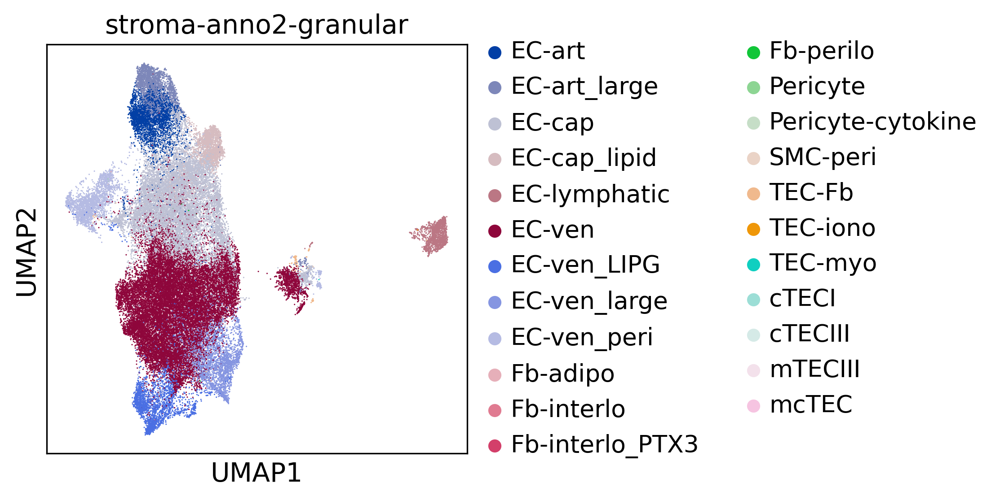

AnnData object with n_obs × n_vars = 54352 × 35530
    obs: 'barcode', 'sample', 'library', 'index', 'library_tcr_ab', 'library_tcr_gd', 'library_bcr', 'path_raw_gex', 'starsolo_version', 'path_cellbender_gex', 'path_cellranger_arc', 'donor', 'chemistry_simple', 'chemistry_detail', 'chemistry_orig', 'origin_institute', 'research_no', 'study', 'sort', 'sort_type', 'in_HTSA', 'public_data', 'type', 'cite', 'health_status', 'age_group', 'age_group2', 'age', 'age_num', 'age_unit', 'age_cont', 'sex', 'age_months', 'path_tcr_ab', 'path_tcr_gd', 'path_bcr', 'comment', 'n_counts', 'n_genes', 'percent_mito', 'percent_ribo', 'percent_hb', 'scrublet_score', 'predicted_doublet', 'taa_l5', 'taa_l4', 'taa_l3', 'taa_l2', 'taa_l1', 'taa_l0', 'doublet', 'stroma-anno1-coarse', 'stroma-anno1-granular', 'stroma-anno2-coarse', 'stroma-anno2-granular', 'doublet_verbose'
    var: 'gene_ids', 'gene_name', 'n_counts', 'n_cells'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'age_group_colors', 'chemistry_simple_

In [18]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
regen_embed(adata, anno2show = 'stroma-anno2-granular')

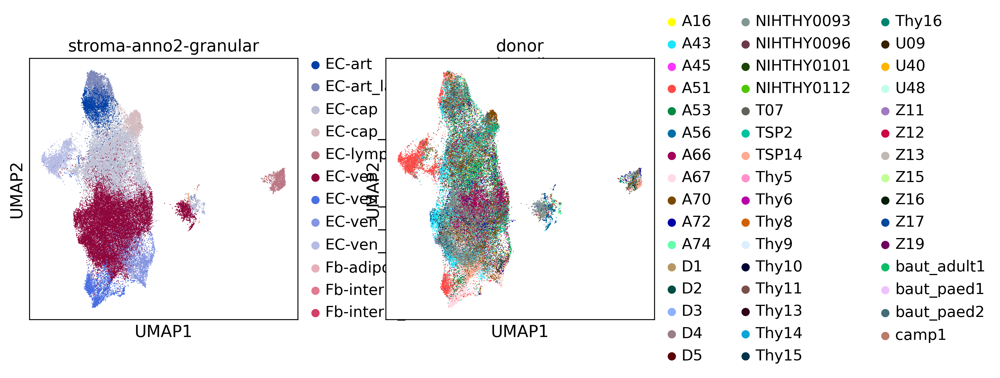

In [19]:
sc.pl.umap(adata, color = ['stroma-anno2-granular', 'donor'])

In [22]:
adata.obs['sample'].value_counts().loc[(adata.obs['sample'].value_counts()<3)].index.tolist()

['Z17-THY-0-SC-1',
 'Thy6',
 'A45-THY-TOT-5GEX',
 'A72-THY-0-SC-1',
 'Z19-THY-0-SC-1',
 'A16_TH_TOT_5GEX_1',
 'A16_TH_TOT_5GEX_4',
 'Thy9',
 'Z16-THY-0-SC-2',
 'Z15-THY-0-SC-EPCP-1',
 'Z15-THY-0-SC-1',
 'A45-THY-CD34P-5GEX',
 'Thy11',
 'U40-THY-0-SC-F-2',
 'Z12-THY--SC-2',
 'Z16-THY-0-SC-45N-1']

In [23]:
adata_temp = adata.copy()
adata = remove_small_samples(adata, sample_anno = 'sample', less_than=3)
adata_temp.shape
adata.shape

['Z17-THY-0-SC-1', 'Thy6', 'A45-THY-TOT-5GEX', 'A72-THY-0-SC-1', 'Z19-THY-0-SC-1', 'A16_TH_TOT_5GEX_1', 'A16_TH_TOT_5GEX_4', 'Thy9', 'Z16-THY-0-SC-2', 'Z15-THY-0-SC-EPCP-1', 'Z15-THY-0-SC-1', 'A45-THY-CD34P-5GEX', 'Thy11', 'U40-THY-0-SC-F-2', 'Z12-THY--SC-2', 'Z16-THY-0-SC-45N-1']
27 cells were removed


(54352, 35530)

(54325, 35530)

In [25]:
del adata_temp
import gc
gc.collect()

751

In [46]:
adata[adata.obs['age_group'] == 'paed'].obs['donor'].value_counts()

donor
Z17           288
Z12           256
NIHTHY0112    172
Z13            30
Z15            19
Name: count, dtype: int64

In [47]:
adata[adata.obs['age_group'] == 'adult'].obs['donor'].value_counts()

donor
baut_adult1    8918
A43            6992
A66            5383
A51            4592
A67            3752
A70            3484
TSP14          3052
NIHTHY0093     3036
TSP2           1535
A53            1062
A56            1007
A72             802
A74             795
Thy15           594
A16             348
Thy16           195
A45              70
Thy14             7
Name: count, dtype: int64

In [24]:
adata.obs['age_group'].value_counts()

age_group
adult     45624
infant     7936
paed        765
Name: count, dtype: int64

Removed excluded genes


An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


Highly variable genes selected in total (54325, 10000)


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/nfs/team205/vk8/mambaforge/envs/scvi-env3/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:441: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=4` in the `DataLoader` to improve performance.
/nfs/team205/vk8/mambaforge/envs/scvi-env3/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:441: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=4` in the `DataLoader` to improve performance.


Epoch 300/300: 100%|██| 300/300 [29:19<00:00,  5.90s/it, v_num=1, train_loss_step=2.63e+3, train_loss_epoch=2.59e+3]

`Trainer.fit` stopped: `max_epochs=300` reached.


Epoch 300/300: 100%|██| 300/300 [29:19<00:00,  5.86s/it, v_num=1, train_loss_step=2.63e+3, train_loss_epoch=2.59e+3]
scVI model trained
UMAP performed


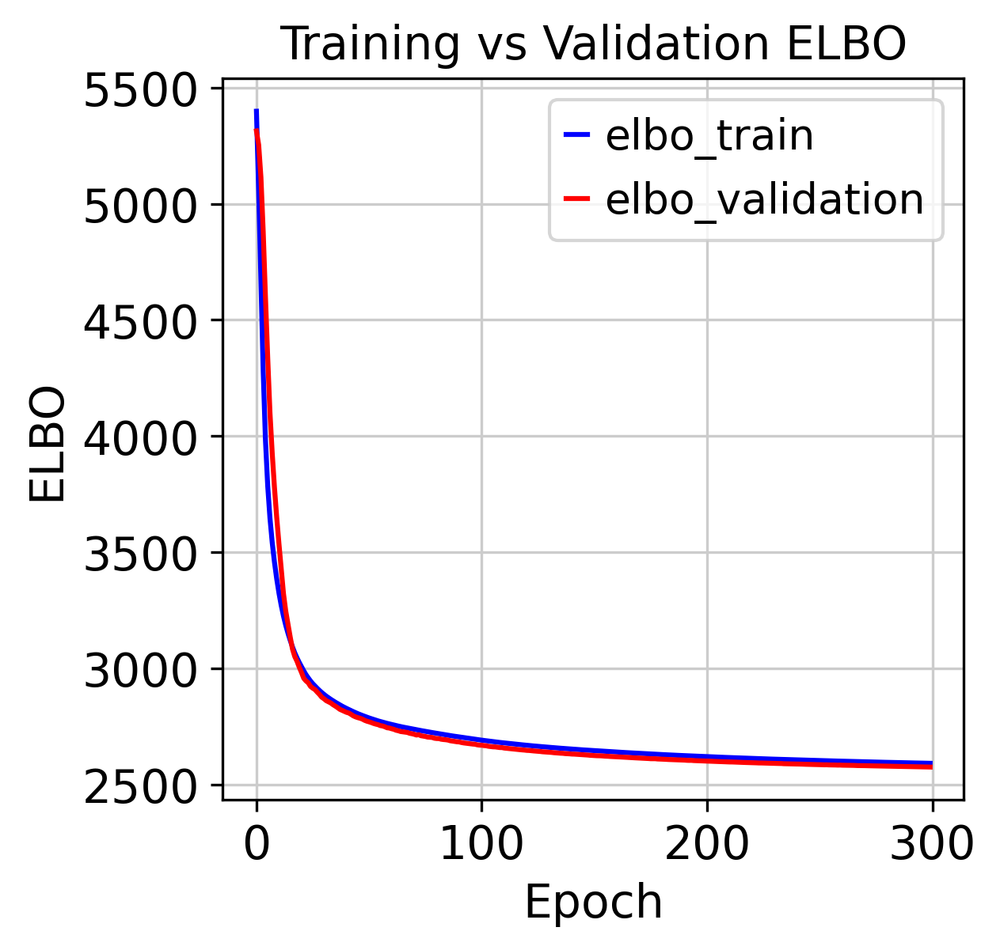

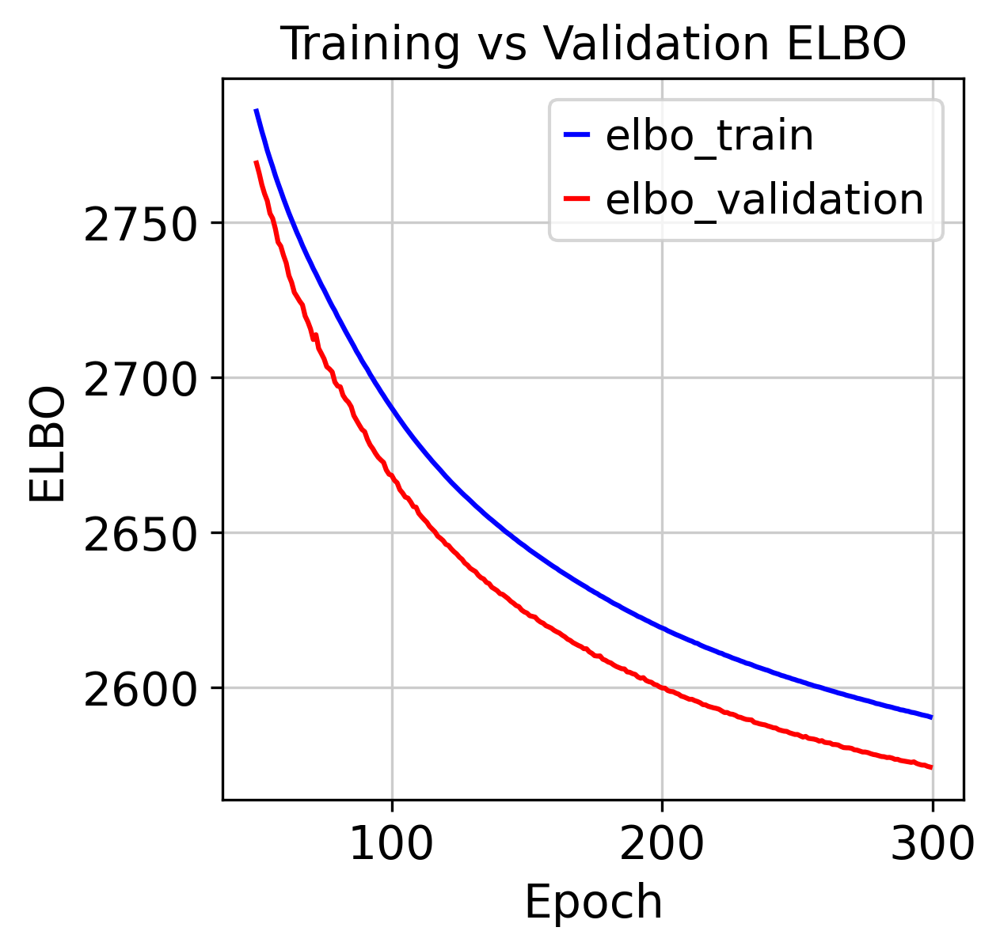

Plotting doublet_metric
Plotting age
Plotting batch_mixing
Plotting cat_covs
Plotting cont_covs


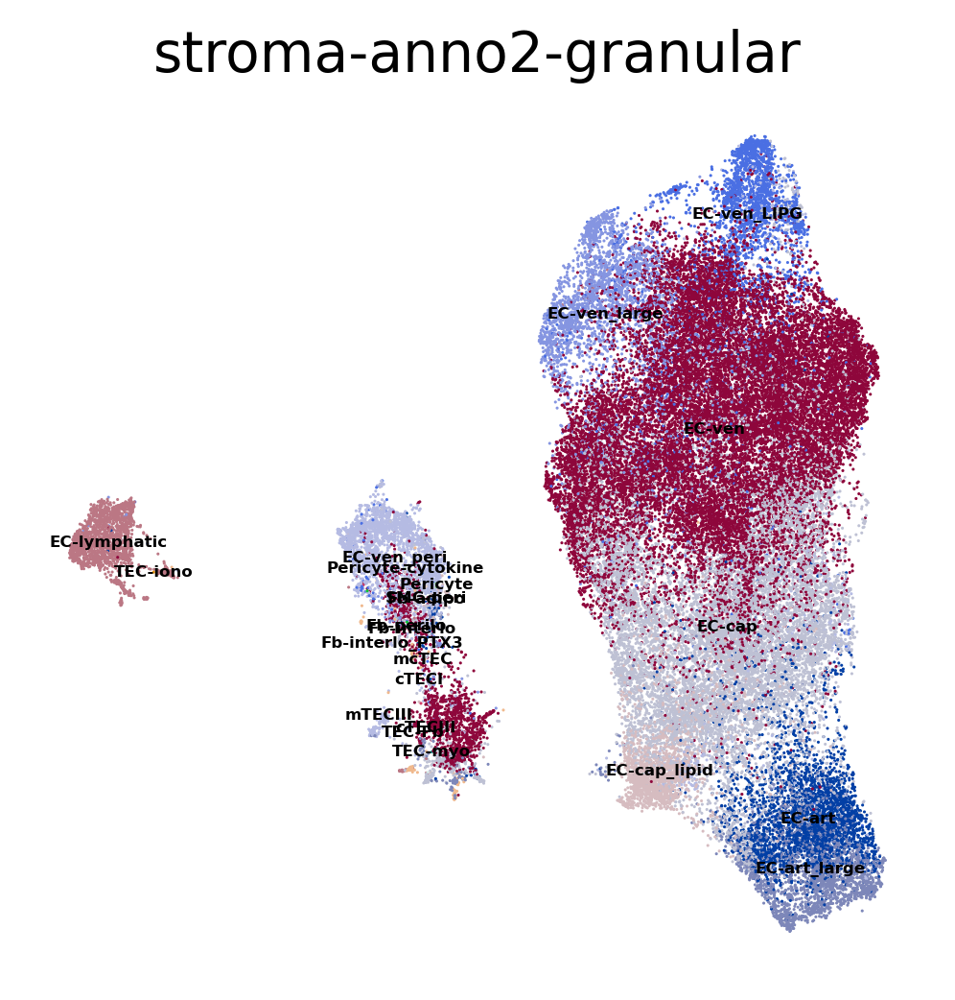

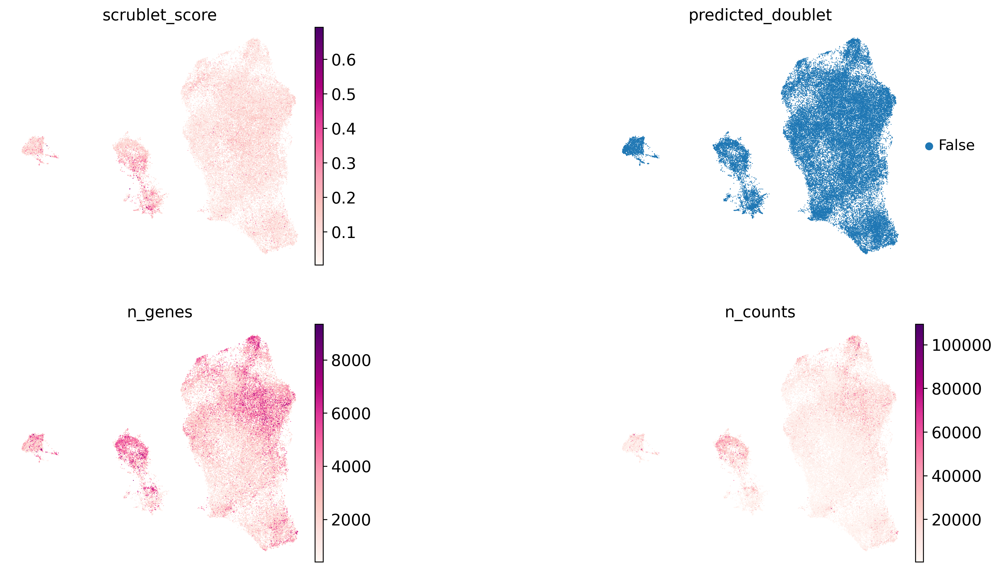

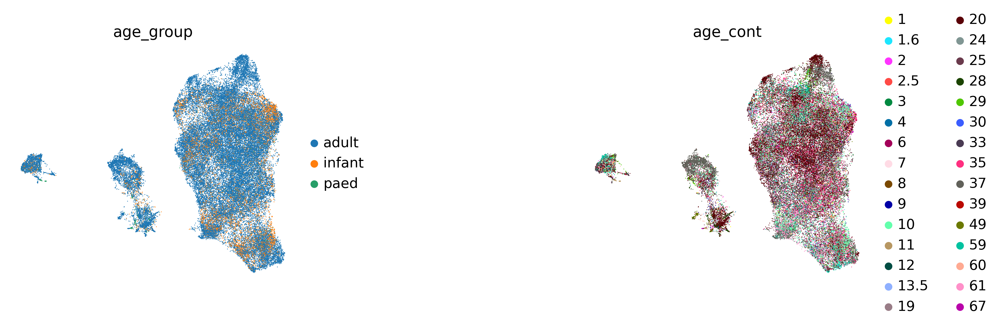

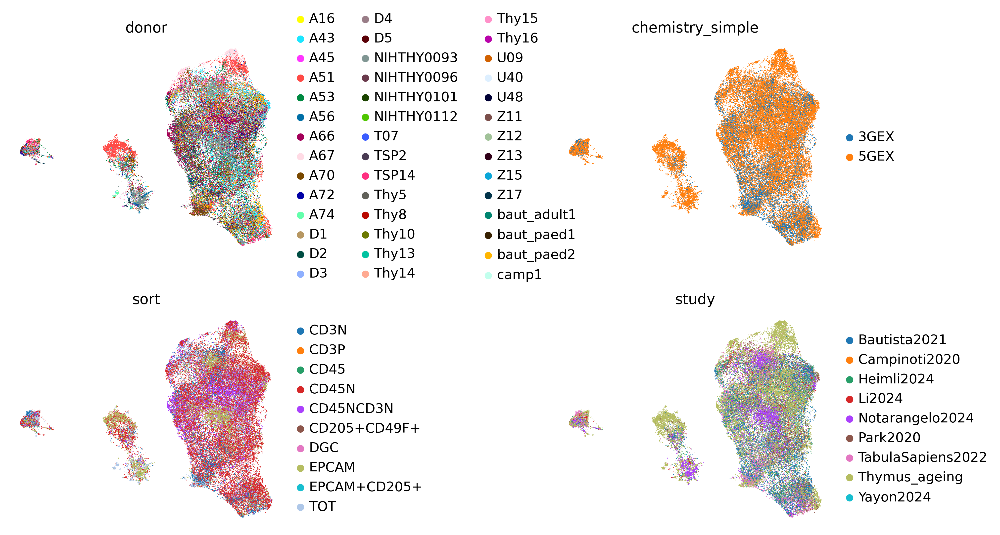

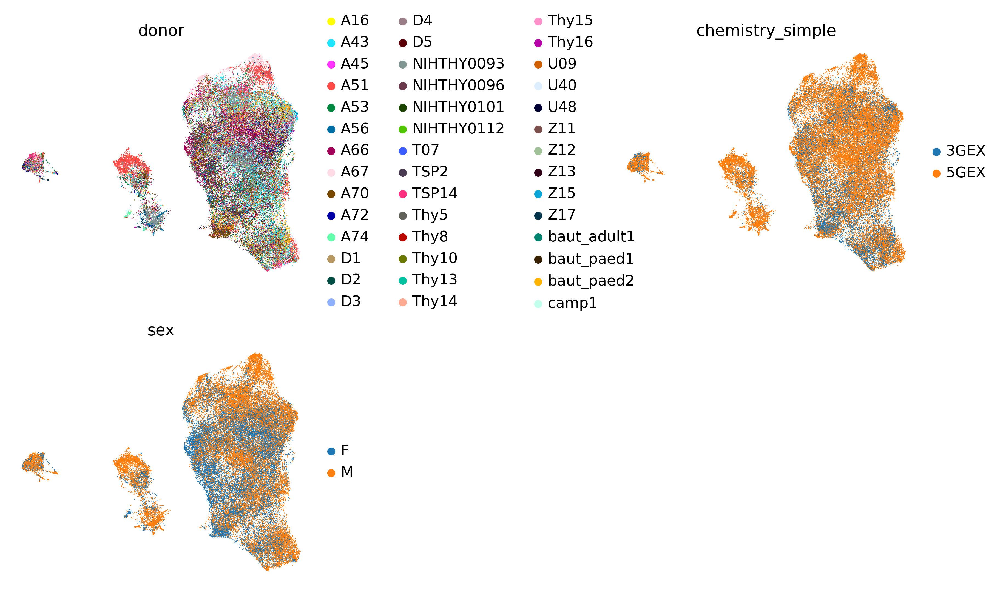

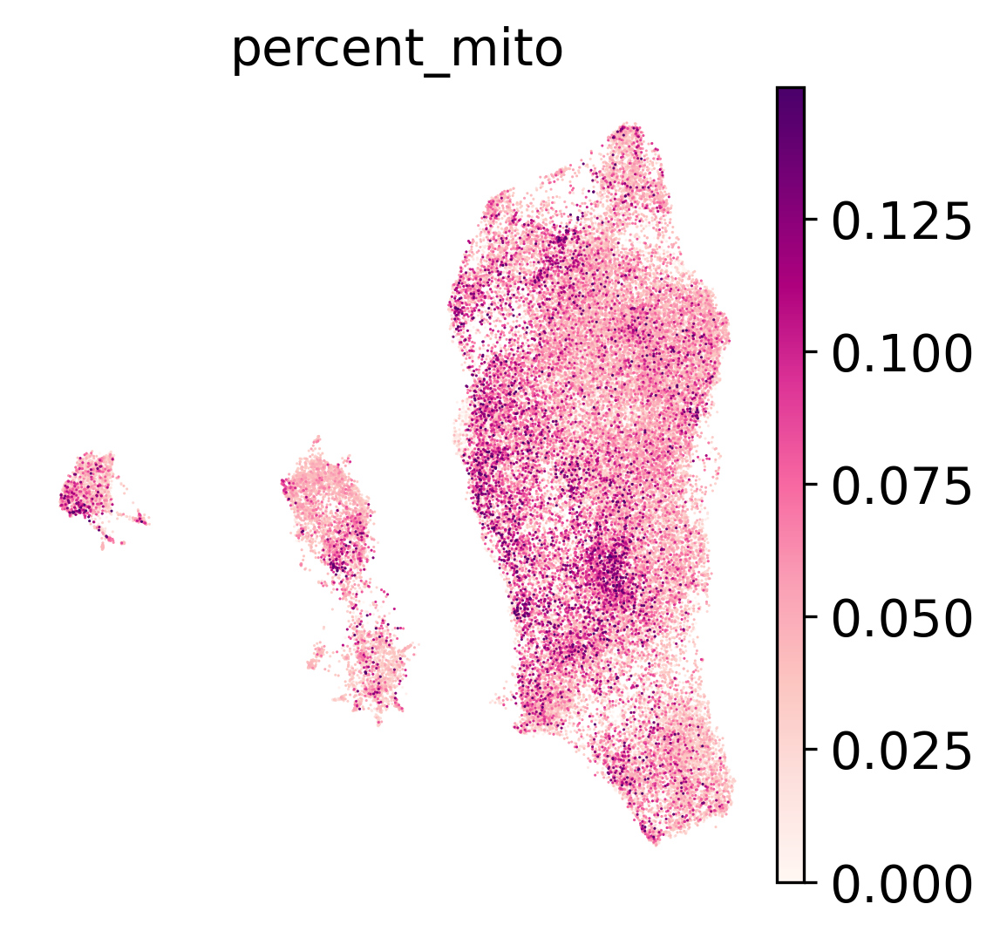

In [26]:
scvi_run2 = run_scvi(adata, 
                    # Excluded genes
                    include_genes=[], exclude_cc_genes=True, exclude_mt_genes=True, 
                    exclude_vdjgenes = True, remove_cite = False,
                    # Highly variable gene selection
                    batch_hv="age_group", hvg = 10000, span = 0.5,
                    # scVI 
                    batch_scvi="sample",
                    cat_cov_scvi=["donor", "chemistry_simple", "sex"], 
                    max_epochs=300, batch_size=2000, early_stopping = False, # early_stopping_patience = 15, early_stopping_min_delta = 10,
                    plan_kwargs = {'lr': 0.0001}, n_layers = 2, n_latent = 30, dispersion = 'gene-batch',
                                      check_val_every_n_epoch = 1,
                    # Leiden clustering
                    leiden_clustering = None, col_cell_type = 'stroma-anno2-granular',
                   covs = {'doublet_metric': ['scrublet_score', 'predicted_doublet', 'n_genes', 'n_counts'],
                    'age': ['age_group', 'age_cont'],
                    'batch_mixing': ['donor', 'chemistry_simple', 'sort', 'study']})

In [30]:
adata = scvi_run2['data'].copy()

In [31]:
del adata_scvi
gc.collect()

108441

In [28]:
# Save adata and scvi model
scvi_embed_version = 'scvi_v3_2024-11-05_tec-fb-vascSplit'
scvi_obj_version = f'vasc_v2_2layers_300epochs_batch-sample{datetime.now().strftime("%Y-%m-%d")}'
overwrite = True

#anno_cols = [c for c in scvi_run['data'].obs.columns if '_pred_' in c or '_prop_' in c]
if not os.path.exists(f'{data_path}/objects/thyAgeing_{scvi_embed_version}_{scvi_obj_version}.zarr') or overwrite:
#    scvi_run['data'].obs = scvi_run['data'].obs.drop(columns=anno_cols)
    scvi_run2['data'].write_h5ad(
        f'{data_path}/objects/thyAgeing_{scvi_embed_version}_{scvi_obj_version}.zarr',
        compression=hdf5plugin.FILTERS["zstd"],
        compression_opts=hdf5plugin.Zstd(clevel=5).filter_options,
    )
    scvi_run2['vae'].save(f'{model_path}/thyAgeing_{scvi_embed_version}_{scvi_obj_version}', save_anndata=True, overwrite=False)
else:
    print('File already exists')


## Redo annotation with celltypist and KNN transfer 

🔬 Input data has 54325 cells and 35530 genes
🔗 Matching reference genes in the model
🧬 6783 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 20
🗳️ Majority voting the predictions
✅ Majority voting done!


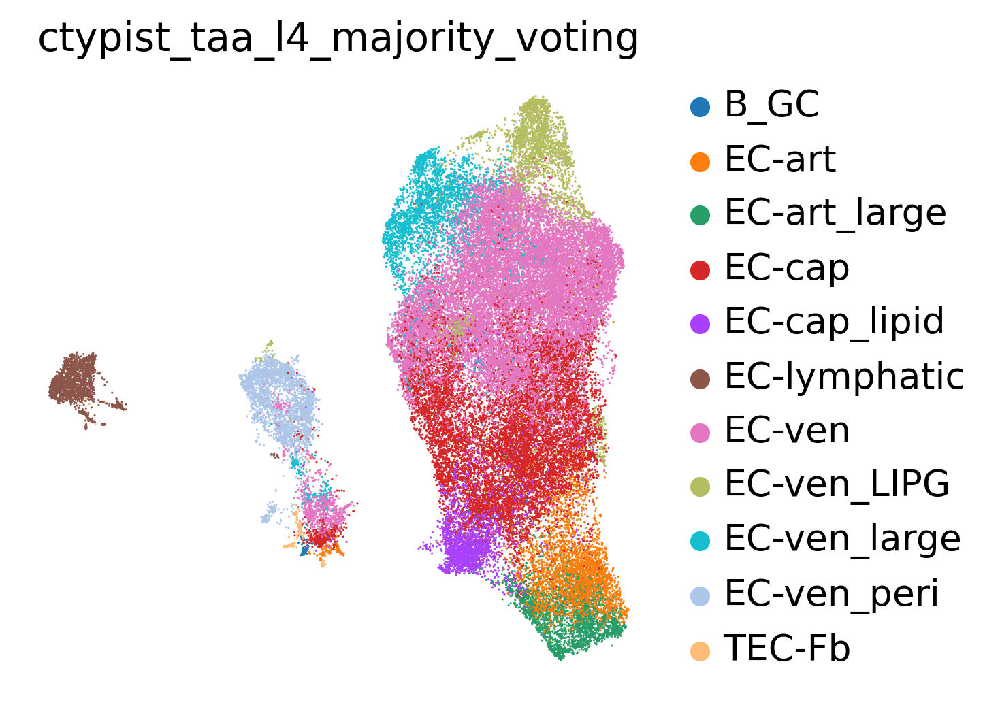

In [33]:
import celltypist
model_taa_l4 = celltypist.Model.load('/lustre/scratch126/cellgen/team205/lm25/thymus_projects/thymus_ageing_atlas/General_analysis/models/Celltypist_mod_thyAge_scvi_v2_pop_mrkrs_taa_l4_2024-12-10.pkl')
ctypist_anno(adata, model = model_taa_l4, col_name = 'taa_l4', mv = True)

In [35]:
dblt_mrkrs = ['PTPRC', 'CD3G', 'CD8A', 'CD8B', 'PDGFRA', 'KRT5', 'KRT8']

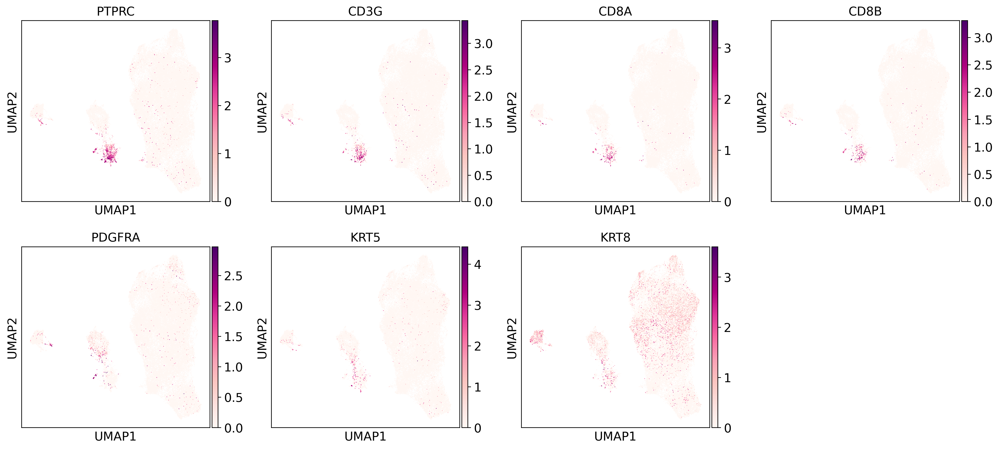

In [36]:
sc.pl.umap(adata, color = dblt_mrkrs)

In [37]:
sc.pl.umap(adata, color = vasc_mrkrs)

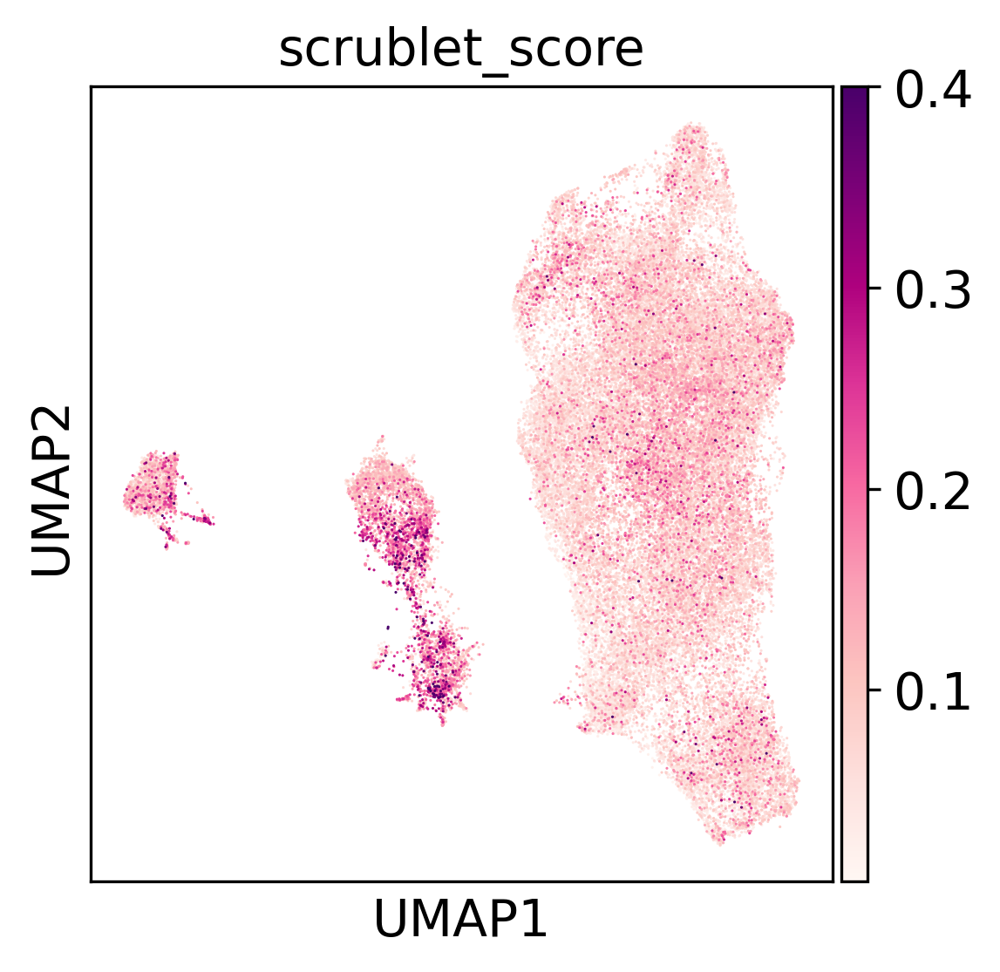

In [40]:
sc.pl.umap(adata, color = ['scrublet_score'], vmax = 0.4)

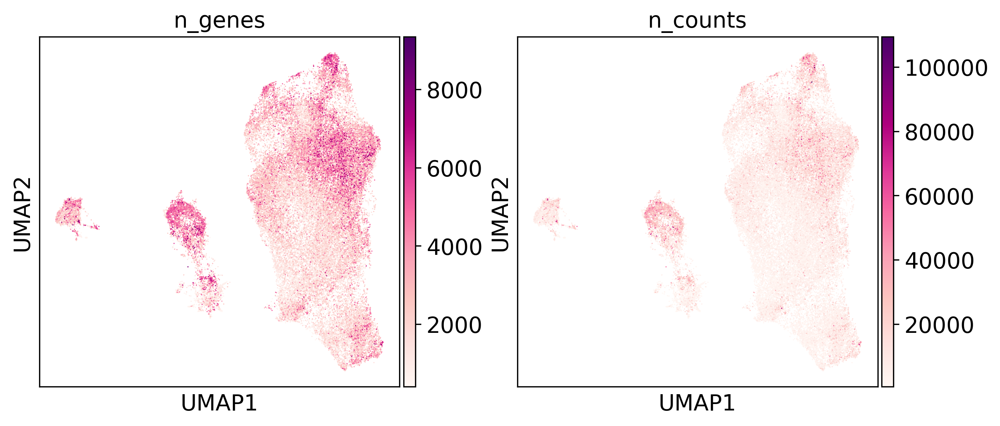

In [55]:
sc.pl.umap(adata, color = ['n_genes', 'n_counts'])

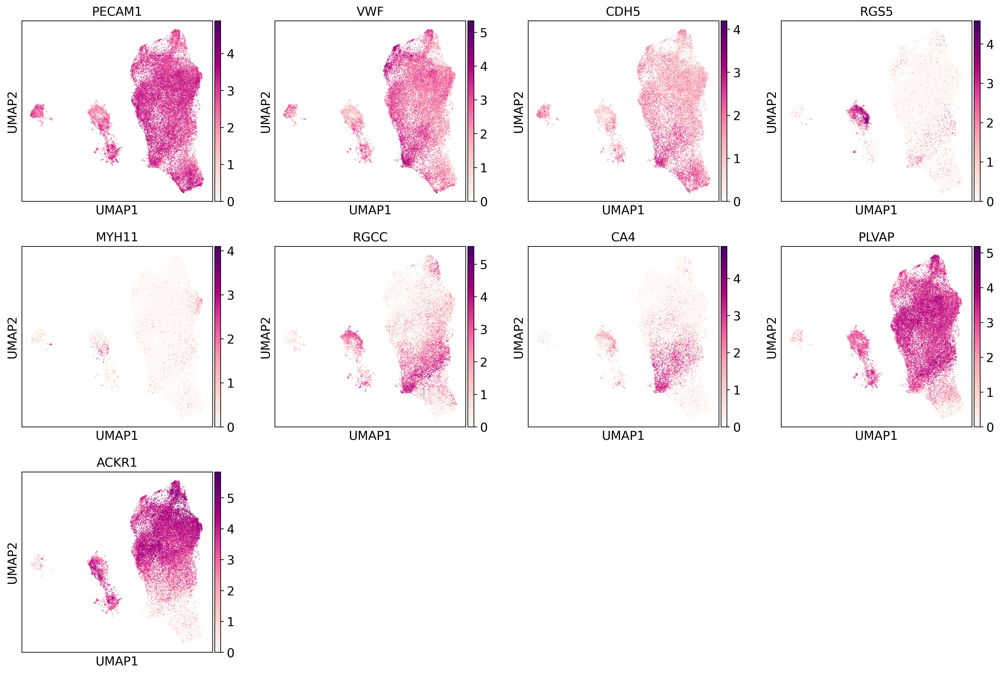

In [101]:
sc.pl.umap(adata, color = ['PECAM1', 'VWF', 'CDH5', 'RGS5', 'MYH11', 'RGCC', 'CA4',  'PLVAP', 'ACKR1'])

In [51]:
old_obs = pd.read_csv(f'{data_path}/thyAgeing_vascSplit_scvi_v3_2layers_300epochs_clean_annotated_2024-05-21.csv')

/tmp/ipykernel_3208950/2738474991.py:1: DtypeWarning: Columns (5,6,7,33,34,35,36) have mixed types. Specify dtype option on import or set low_memory=False.
  old_obs = pd.read_csv(f'{data_path}/thyAgeing_vascSplit_scvi_v3_2layers_300epochs_clean_annotated_2024-05-21.csv')


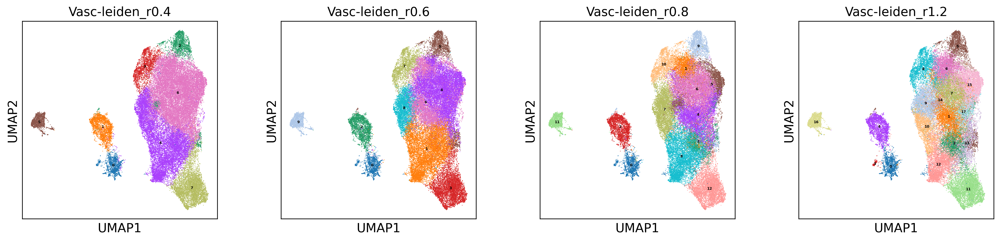

In [56]:
run_leiden(adata, resolutions = [0.4, 0.6, 0.8, 1.2], key_name = 'Vasc')

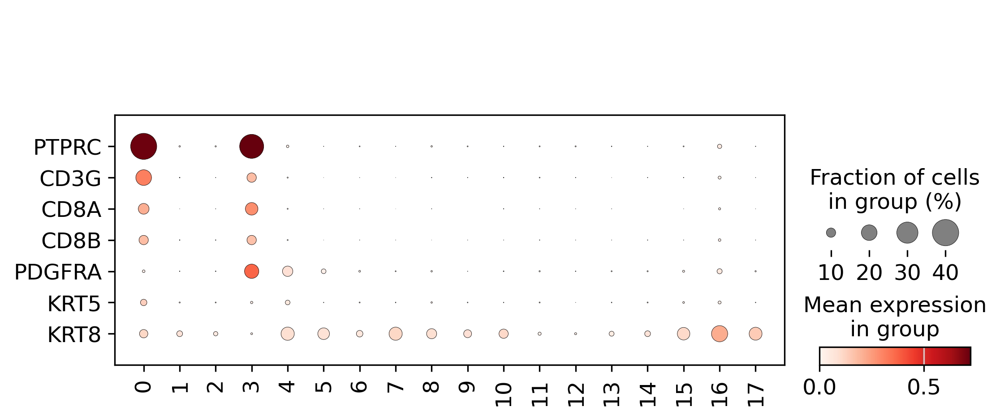

In [58]:
sc.pl.dotplot(adata, var_names = dblt_mrkrs, groupby = 'Vasc-leiden_r1.2', swap_axes = True)

In [89]:
sc.tl.dendrogram(adata, groupby = 'Vasc-leiden_r1.2', use_rep = 'X_scVI')

categories: 0, 1, 2, etc.
var_group_labels: pan-vasc, large vassels, large_art_ec, etc.


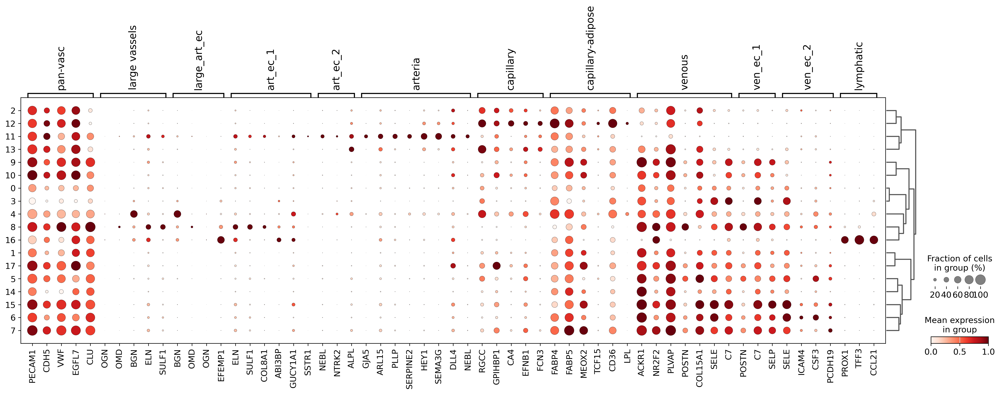

In [95]:
sc.pl.dotplot(adata, var_names = vasc_mrkrs_dict, groupby = 'Vasc-leiden_r1.2', swap_axes = False, 
             standard_scale='var', dendrogram=True)

In [103]:
adata.obs['EC_anno1'] = adata.obs['Vasc-leiden_r1.2'].apply(lambda x:
                            'EC-lymphatic' if x == '16' else
                            'EC-T-doublet' if x in ['0', '3'] else 
                            'EC-peri' if x == '4' else # donor-specific cluster
                            'EC-blood')

In [104]:
adata.obs[['EC_anno1']].to_csv(f'{data_path}/objects/thyAgeing_{scvi_obj_version}_anno_v1.csv')

In [105]:
adata.obs['EC_anno1'].value_counts()

EC_anno1
EC-blood        47188
EC-peri          3103
EC-T-doublet     2131
EC-lymphatic     1903
Name: count, dtype: int64

... Perform several rounds of annotation 

In [199]:
adata_dbrm.obs['EC_anno2'] = adata_dbrm.obs.apply(lambda x: x['EC_lymph_anno'] if x['EC_anno1'] == 'EC-lymphatic' else
                                                 x['EC_peri_anno'] if x['EC_anno1'] == 'EC-peri' else
                                                 x['EC_blood_anno'], axis = 1)

... storing 'EC_anno2' as categorical


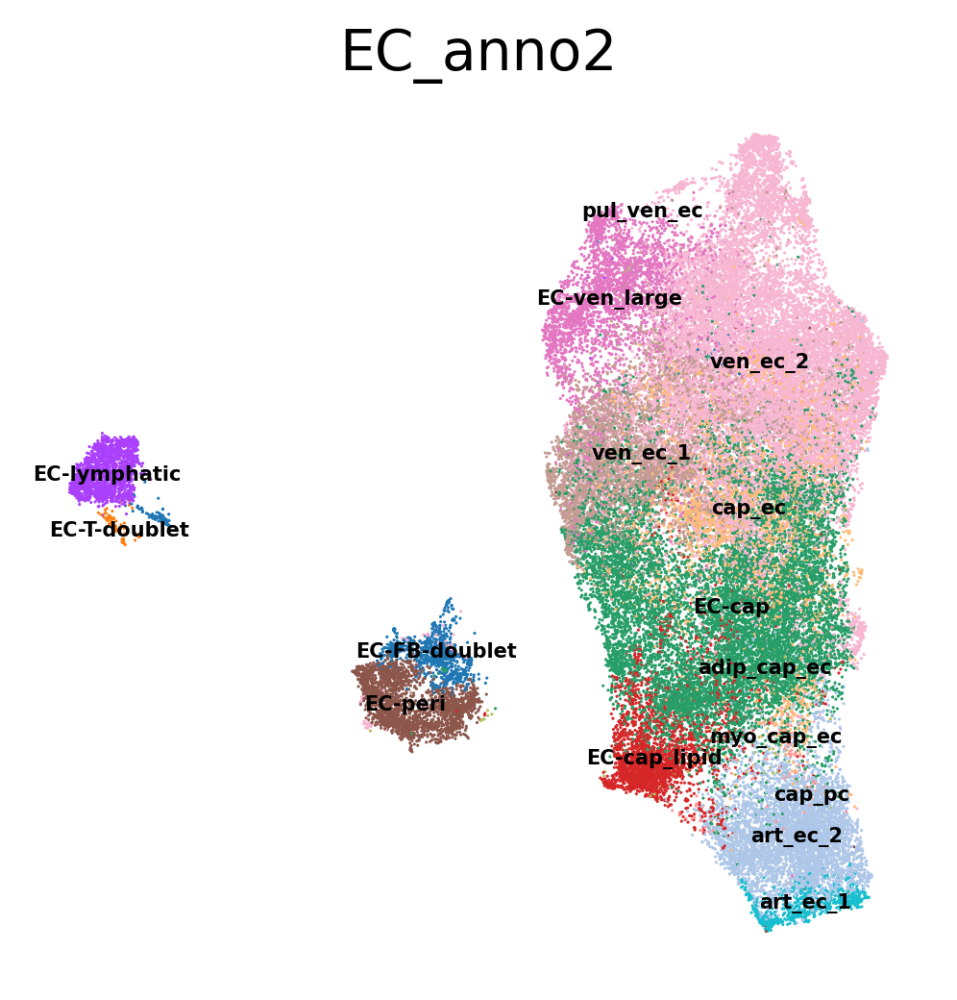

In [200]:
sc.pl.umap(adata_dbrm, color = 'EC_anno2', legend_loc = 'on data', legend_fontsize = 5, frameon = False)

In [203]:
adata_dbrm.obs['EC_anno2'].value_counts()

EC_anno2
ven_ec_2         15460
EC-cap           11854
ven_ec_1          5189
art_ec_2          4867
EC-ven_large      3208
cap_ec            2936
EC-cap_lipid      2639
EC-peri           2224
EC-lymphatic      1675
EC-FB-doublet      993
art_ec_1           702
myo_cap_ec         202
adip_cap_ec        122
EC-T-doublet       118
pul_ven_ec           4
cap_pc               1
Name: count, dtype: int64

In [204]:
adata_dbrm.obs['EC_anno3'] = adata_dbrm.obs['EC_anno2'].apply(lambda x: 'EC-cap' if x in ['myo_cap_ec', 'cap_ec','cap_pc'] else
                                                              'EC-ven_large' if x == 'pul_ven_ec' else
                                                             'EC-cap_lipid' if x == 'adip_cap_ec' else
                                                             'EC-art_large' if x == 'art_ec_1' else
                                                             'EC_art' if x == 'art_ec_2' else
                                                             'EC-ven1' if x == 'ven_ec_1' else
                                                             'EC-ven2' if x == 'ven_ec_2' else x) 

... storing 'EC_anno3' as categorical


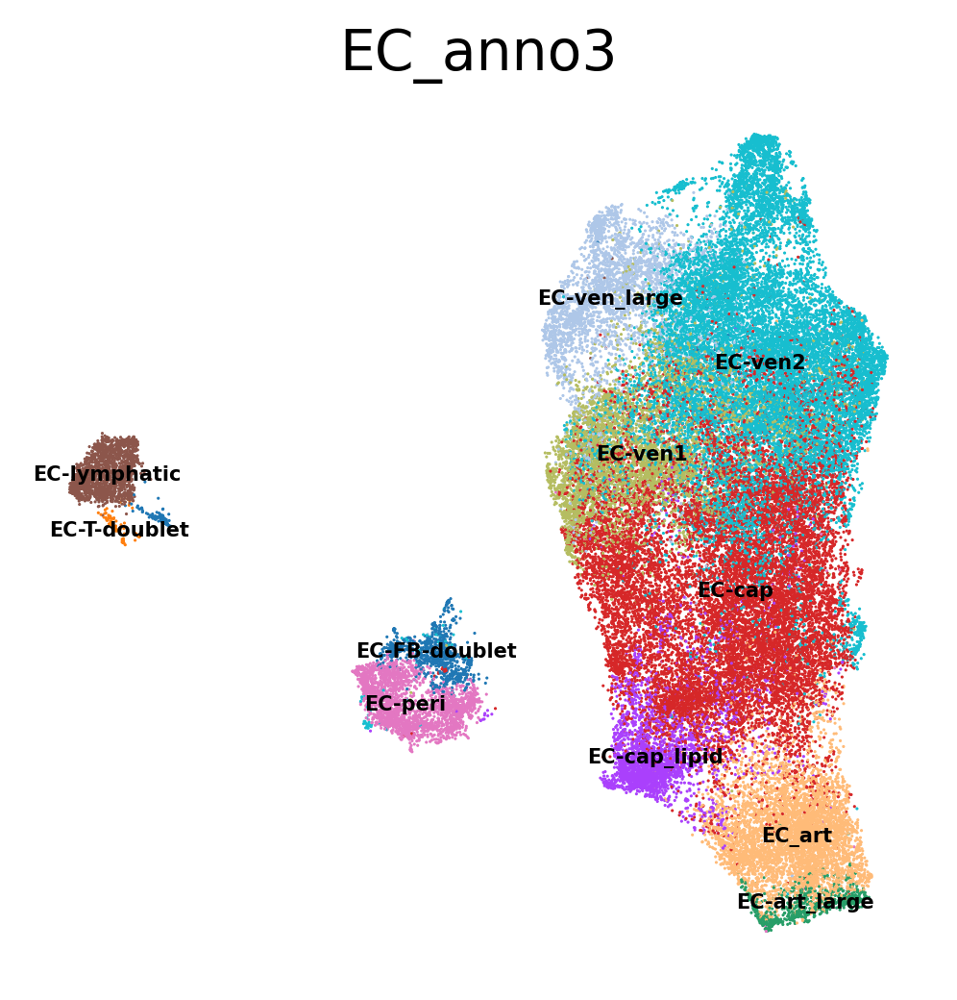

In [205]:
sc.pl.umap(adata_dbrm, color = 'EC_anno3', legend_loc = 'on data', legend_fontsize = 5, frameon = False)

In [222]:
annotations[['EC_anno2', 'EC_anno3']] = adata_dbrm.obs.reindex(annotations.index)[['EC_anno2', 'EC_anno3']].copy()

In [225]:
annotations['EC_anno'] = annotations.apply (lambda x: x['EC_anno3'] if not pd.isnull(x['EC_anno3']) else 
                                            x['EC_anno1'], axis = 1)

In [227]:
annotations.to_csv(f'{data_path}/objects/thyAgeing_{scvi_obj_version}_anno_v2.csv')

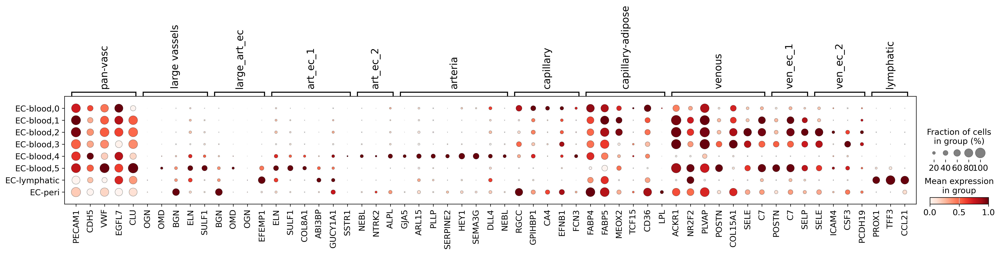

In [124]:
sc.pl.dotplot(adata_dbrm, var_names = vasc_mrkrs_dict, groupby = 'leiden_EC-blood-leiden_r0.4', standard_scale = 'var')

In [231]:
def scvi_markers_enrich(vae, cluster, adata, prep_vae = True, enrich = True, n_markers=5):
    if prep_vae:
        vae.adata.obs[cluster] = adata.obs.reindex(vae.adata.obs_names)[cluster].copy()
    results = {}
    de_mrks_dict = {}
    de_df = vae.differential_expression(
    groupby=cluster)
    de_df['cluster'] = [i.replace(" vs Rest","") for i in de_df['comparison']]
    de_df.head()
    markers = {}
    cats = vae.adata.obs[cluster].cat.categories
    for i, c in enumerate(cats):
        cid = "{} vs Rest".format(c)
        cell_type_df = de_df.loc[de_df.comparison == cid]
        cell_type_df = cell_type_df[cell_type_df.lfc_mean > 1]
        cell_type_df = cell_type_df[cell_type_df["bayes_factor"] > 2]
        cell_type_df = cell_type_df[cell_type_df["non_zeros_proportion1"] > 0.1]
        de_mrks_dict[c]=cell_type_df.index.tolist() 
        markers[c] = cell_type_df.index.tolist()[:n_markers]
    if enrich:
        enrich_df = sc.queries.enrich(de_mrks_dict,gprofiler_kwargs={'sources': ['GO:BP', 'REAC', 'KEGG'], 
                                                                     'no_evidences': False, 'all_results': True}, 
                                      org="hsapiens")
        enrich_df.significant = enrich_df.p_value<0.1
        enrich_df = enrich_df.loc[((enrich_df.term_size > 10) & (enrich_df.term_size < 500)) & (enrich_df.significant == True)].reset_index(drop = True)
        print(f"Number of significant genes:{str(enrich_df.significant.sum())}")
    results['de_df'] = de_df
    results['markers'] = markers
    results['enrich'] = enrich_df
    #print(results)
    return(results)


In [232]:
vasc_mrkrs_scvi = scvi_markers_enrich(vae = scvi_run2['vae'], 
                                      cluster = 'EC_anno3', 
                                      adata = adata_dbrm, prep_vae = True, enrich = True, n_markers=5)

DE...: 100%|████████████████████████████████████████████████████████████████████████| 11/11 [02:48<00:00, 15.29s/it]
Number of significant genes:1541


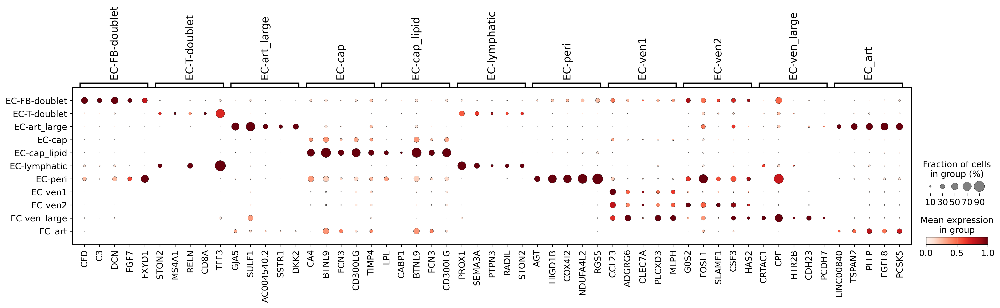

In [233]:
sc.pl.dotplot(adata_dbrm, var_names = vasc_mrkrs_scvi['markers'], groupby='EC_anno3', standard_scale='var')

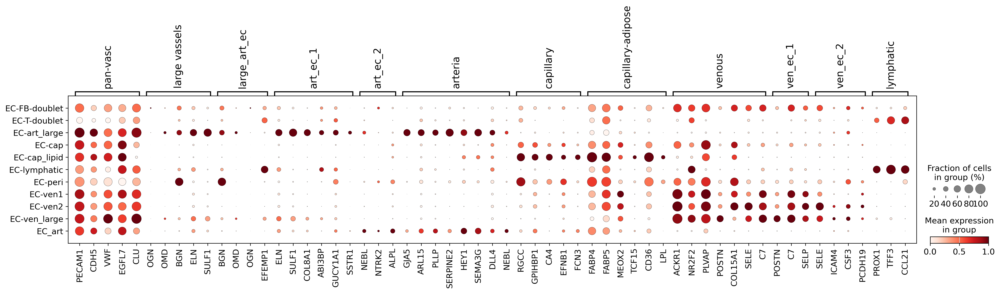

In [234]:
sc.pl.dotplot(adata_dbrm, var_names = vasc_mrkrs_dict, groupby='EC_anno3', standard_scale='var')

In [240]:
pd.crosstab(index = adata_dbrm.obs['age_group'], columns = adata_dbrm.obs['age'])

age,1.6m,2.5m,3m,4m,6d,6m,6y,7d,8y,9m,9y,10m,10y,11m,11y,12m,13.5m,19y,20y,24y,25y,28y,29y,30m,33y,35y,37y,39y,49y,59y,60y,61y,67y
age_group,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
adult,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,69,11552,336,8896,543,1053,0,767,6953,7936,7,488,3018,549,1504,140
infant,380,222,86,75,43,68,0,1401,0,548,0,3261,0,94,0,4,1548,0,0,0,0,0,11,11,0,0,0,0,0,0,0,0,0
paed,0,0,0,0,0,0,29,0,244,0,154,0,19,0,185,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [237]:
adata_dbrm.obs['age_group'].cat.categories

Index(['adult', 'infant', 'paed'], dtype='object')

In [239]:
adata_dbrm.obs

,barcode,sample,library,index,library_tcr_ab,library_tcr_gd,library_bcr,path_raw_gex,starsolo_version,path_cellbender_gex,path_cellranger_arc,donor,chemistry_simple,chemistry_detail,chemistry_orig,origin_institute,research_no,study,sort,sort_type,in_HTSA,public_data,type,cite,health_status,age_group,age_group2,age,age_num,age_unit,age_cont,sex,age_months,path_tcr_ab,path_tcr_gd,path_bcr,comment,n_counts,n_genes,percent_mito,percent_ribo,percent_hb,scrublet_score,predicted_doublet,taa_l5,taa_l4,taa_l3,taa_l2,taa_l1,taa_l0,doublet,stroma-anno1-coarse,stroma-anno1-granular,stroma-anno2-coarse,stroma-anno2-granular,doublet_verbose,ctypist_taa_l4_predicted_labels,ctypist_taa_l4_over_clustering,ctypist_taa_l4_majority_voting,ctypist_taa_l4_conf_score,Vasc-leiden_r0.4,Vasc-leiden_r0.6,Vasc-leiden_r0.8,Vasc-leiden_r1.2,Vasc_anno1,EC_anno1,leiden_EC-blood-leiden_r0.4,leiden_EC-blood-leiden_r0.6,leiden_EC-blood-leiden_r0.8,leiden_EC-peri-leiden_r0.2,leiden_EC-peri-leiden_r0.4,leiden_EC-lymphatic-leiden_r0.1,leiden_EC-lymphatic-leiden_r0.2,ctypist_vasc_predicted_labels,ctypist_vasc_conf_score,ctypist_vasc_over_clustering,ctypist_vasc_majority_voting,leiden_EC-blood-leiden_r1.0,leiden_EC-blood-leiden_r1.2,leiden_EC-blood-leiden_r0.9,EC_lymph_anno,EC_peri_anno,EC_blood_anno,EC_anno2,EC_anno3
names,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
FCAImmP8111789-GAACGGAAGGCTAGAC,GAACGGAAGGCTAGAC,A45-THY-EPCAM-5GEX,FCAImmP8111789,FCAImmP8111789,NaN,NaN,NaN,/nfs/team205/vk8/irods_data/09_thymus/starsolo...,2.7.4a,/lustre/scratch126/cellgen/team205/sharedData/...,nan,A45,5GEX,10x 5' v1.0,5'v1,CBTM,19/0067,Park2020,EPCAM,MACS,no,no,cells,False,healthy,adult,adult(early),19y,19,y,19,M,228.0,NaN,NaN,NaN,NaN,4646,1492,0.052088,0.335342,0.000000,0.185930,False,NaN,NaN,NaN,NaN,NaN,NaN,non-doublet,TEC,mcTEC,EC,EC-ven,NaN,EC-ven_peri,331,EC-ven_large,0.364875,1,2,3,4,Vasc,EC-peri,EC-peri,EC-peri,EC-peri,"EC-peri,0","EC-peri,0",EC-peri,EC-peri,ven_ec_1,0.191460,366,ven_ec_1,EC-peri,EC-peri,EC-peri,NaN,EC-FB-doublet,EC-ven_large,EC-FB-doublet,EC-FB-doublet
FCAImmP8111789-CGTCAGGAGAGATGAG,CGTCAGGAGAGATGAG,A45-THY-EPCAM-5GEX,FCAImmP8111789,FCAImmP8111789,NaN,NaN,NaN,/nfs/team205/vk8/irods_data/09_thymus/starsolo...,2.7.4a,/lustre/scratch126/cellgen/team205/sharedData/...,nan,A45,5GEX,10x 5' v1.0,5'v1,CBTM,19/0067,Park2020,EPCAM,MACS,no,no,cells,False,healthy,adult,adult(early),19y,19,y,19,M,228.0,NaN,NaN,NaN,NaN,3218,1218,0.066501,0.226538,0.000000,0.208791,False,EC-ven_peri,EC-ven_peri,EC-ven,EC-ven,EC,Vascular,non-doublet,EC,EC-ven_peri,EC,EC-ven_peri,NaN,EC-ven_peri,151,EC-ven_peri,0.992797,1,2,3,4,Vasc,EC-peri,EC-peri,EC-peri,EC-peri,"EC-peri,0","EC-peri,0",EC-peri,EC-peri,ven_ec_2,0.845845,29,ven_ec_2,EC-peri,EC-peri,EC-peri,NaN,EC-FB-doublet,ven_ec_2,EC-FB-doublet,EC-FB-doublet
GSM4466786-GAATCGTCATGGCGCT,GAATCGTCATGGCGCT,baut7,GSM4466786,GSM4466786,NaN,NaN,NaN,/nfs/team205/vk8/irods_data/09_thymus/starsolo...,2.7.4a,/lustre/scratch126/cellgen/team205/sharedData/...,nan,baut_adult1,3GEX,10x 3' v2.0,10x 3' v2 or v3,Bautista2021,NaN,Bautista2021,CD45N,FACS,no,yes,cells,False,healthy,adult,adult(early),25y,25,y,25,F,300.0,NaN,NaN,NaN,NaN,10724,3651,0.058094,0.153767,0.000093,0.213793,False,NaN,NaN,NaN,NaN,NaN,NaN,non-doublet,EC,EC-cap,EC,EC-ven_peri,NaN,EC-ven_peri,22,EC-ven_peri,0.746707,1,2,3,4,Vasc,EC-peri,EC-peri,EC-peri,EC-peri,"EC-peri,0","EC-peri,1",EC-peri,EC-peri,bridging_lec,0.062382,24,art_ec_2,EC-peri,EC-peri,EC-peri,NaN,EC-peri,art_ec_2,EC-peri,EC-peri
GSM4466786-CCACGTTGTGACAGCA,CCACGTTGTGACAGCA,baut7,GSM4466786,GSM4466786,NaN,NaN,NaN,/nfs/team205/vk8/irods_data/09_thymus/starsolo...,2.7.4a,/lustre/scratch126/cellgen/team205/sharedData/...,nan,baut_adult1,3GEX,10x 3' v2.0,10x 3' v2 or v3,Bautista2021,NaN,Bautista2021,CD45N,FACS,no,yes,cells,False,healthy,adult,adult(early),25y,25,y,25,F,300.0,NaN,NaN,NaN,NaN,6972,2540,0.068273,0.150889,0.000430,0.097625,False,NaN,NaN,NaN,NaN,NaN,NaN,non-doublet,TEC,TEC-F

## Reload integrated object

In [10]:
adata = ad.read_h5ad('/nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/data/objects/thyAgeing_scvi_v3_2024-11-05_tec-fb-vascSplit_vasc_v2_2layers_300epochs_batch-sample2025-01-25.zarr')

annotations = pd.read_csv('/nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/data/objects/thyAgeing_vasc_v2_2layers_300epochs_batch-sample2025-01-25_anno_v2.csv', index_col = 0)

In [12]:
adata.obs[['EC_anno3', 'EC_anno']] = annotations.reindex(adata.obs_names)[['EC_anno3', 'EC_anno']].copy()

In [15]:
doublets = [i for i in adata.obs['EC_anno'].unique().tolist() if 'doublet' in i]

In [16]:
adata_dbrm = adata[~adata.obs['EC_anno'].isin(doublets),].copy()

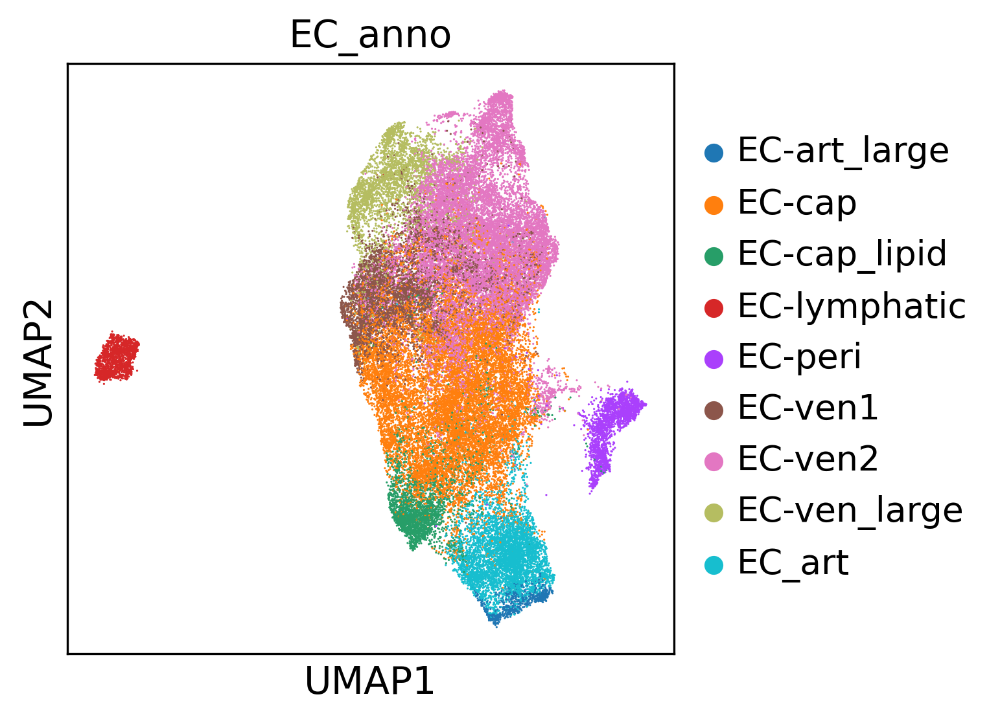

AnnData object with n_obs × n_vars = 51083 × 35530
    obs: 'barcode', 'sample', 'library', 'index', 'library_tcr_ab', 'library_tcr_gd', 'library_bcr', 'path_raw_gex', 'starsolo_version', 'path_cellbender_gex', 'path_cellranger_arc', 'donor', 'chemistry_simple', 'chemistry_detail', 'chemistry_orig', 'origin_institute', 'research_no', 'study', 'sort', 'sort_type', 'in_HTSA', 'public_data', 'type', 'cite', 'health_status', 'age_group', 'age_group2', 'age', 'age_num', 'age_unit', 'age_cont', 'sex', 'age_months', 'path_tcr_ab', 'path_tcr_gd', 'path_bcr', 'comment', 'n_counts', 'n_genes', 'percent_mito', 'percent_ribo', 'percent_hb', 'scrublet_score', 'predicted_doublet', 'taa_l5', 'taa_l4', 'taa_l3', 'taa_l2', 'taa_l1', 'taa_l0', 'doublet', 'stroma-anno1-coarse', 'stroma-anno1-granular', 'stroma-anno2-coarse', 'stroma-anno2-granular', 'doublet_verbose', 'EC_anno3', 'EC_anno'
    var: 'gene_ids', 'gene_name', 'n_counts', 'n_cells'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'age_cont_color

In [17]:
regen_embed(adata_dbrm, 'EC_anno')

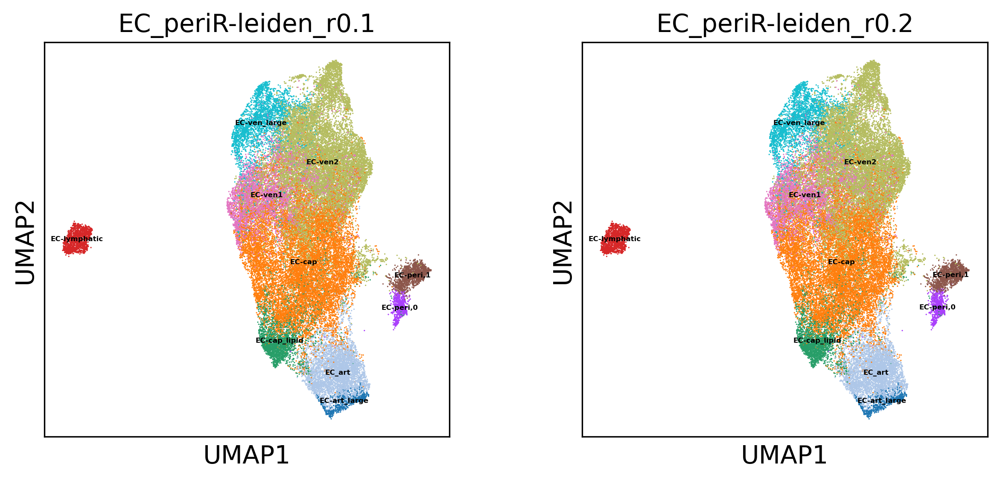

In [37]:
run_leiden(adata_dbrm, resolutions=[0.1, 0.2], restrict_to=['EC_anno', ['EC-peri']], key_name = 'EC_periR')

In [77]:
adata_dbrm.obs['EC_periR-leiden_r0.1'].value_counts()

EC_periR-leiden_r0.1
EC-ven2         15460
EC-cap          14993
EC-ven1          5189
EC_art           4867
EC-ven_large     3212
EC-cap_lipid     2761
EC-lymphatic     1675
EC-peri,1        1546
EC-art_large      702
EC-peri,0         678
Name: count, dtype: int64

In [31]:
import celltypist
from celltypist import models
vasc_model = models.Model.load(model = 'Adult_Human_Vascular.pkl')

🔬 Input data has 51083 cells and 35530 genes
🔗 Matching reference genes in the model
🧬 3520 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 20
🗳️ Majority voting the predictions
✅ Majority voting done!


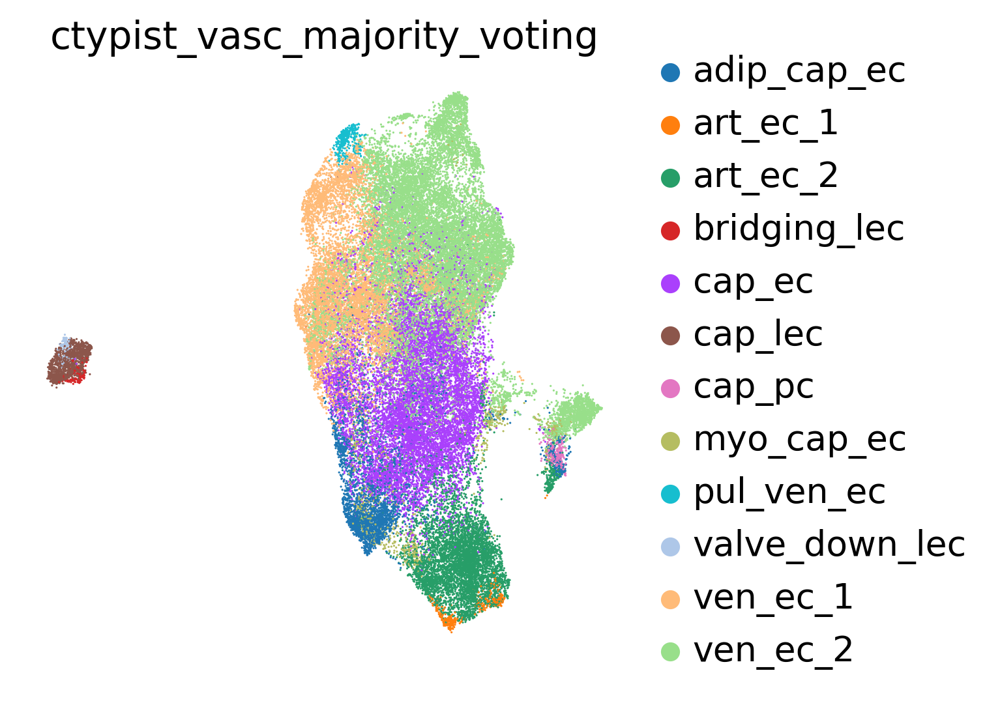

In [32]:
ctypist_anno (adata_dbrm, model = vasc_model, col_name = 'vasc', mv=True)

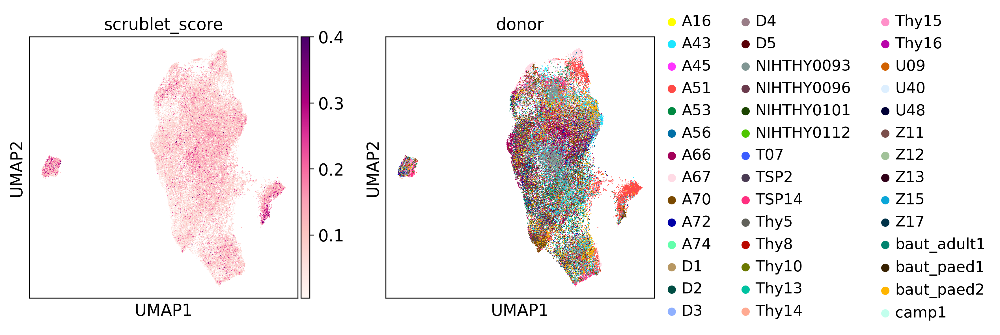

In [36]:
sc.pl.umap(adata_dbrm, color = ['scrublet_score', 'donor'], vmax = 0.4)

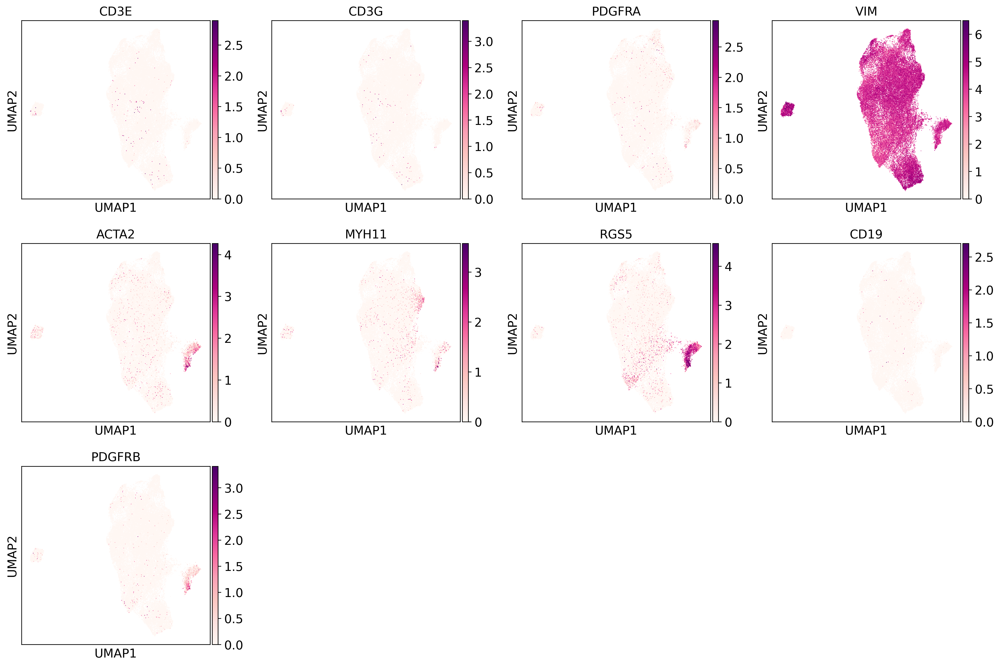

In [43]:
sc.pl.umap(adata_dbrm, color = ['CD3E', 'CD3G', 'PDGFRA', 'VIM', 'ACTA2', 'MYH11', 'RGS5', 'CD19', 'PDGFRB'])

In [49]:
adata_dbrm.obs['EC_anno4'] = adata_dbrm.obs.apply(lambda x: 
                            'EC-ven_large' if (x['EC_anno'] == 'EC-ven_large') & (x['EC_annoR-leiden_r0.4'] in ['EC-ven_large,4', 'EC-ven_large,2']) else
                            'EC-ven1' if (x['EC_anno'] == 'EC-ven_large') & (x['ctypist_vasc_majority_voting'] == 'ven_ec_1') else
                            'EC-ven2' if (x['EC_anno'] == 'EC-ven_large') & (x['ctypist_vasc_majority_voting'] == 'ven_ec_2') else
                            'EC-art' if x['EC_anno']== 'EC_art' else
                            'EC-peri-doublet' if x['EC_periR-leiden_r0.1']=='EC-peri,0' else x['EC_anno'], axis = 1)                                 

... storing 'EC_anno4' as categorical


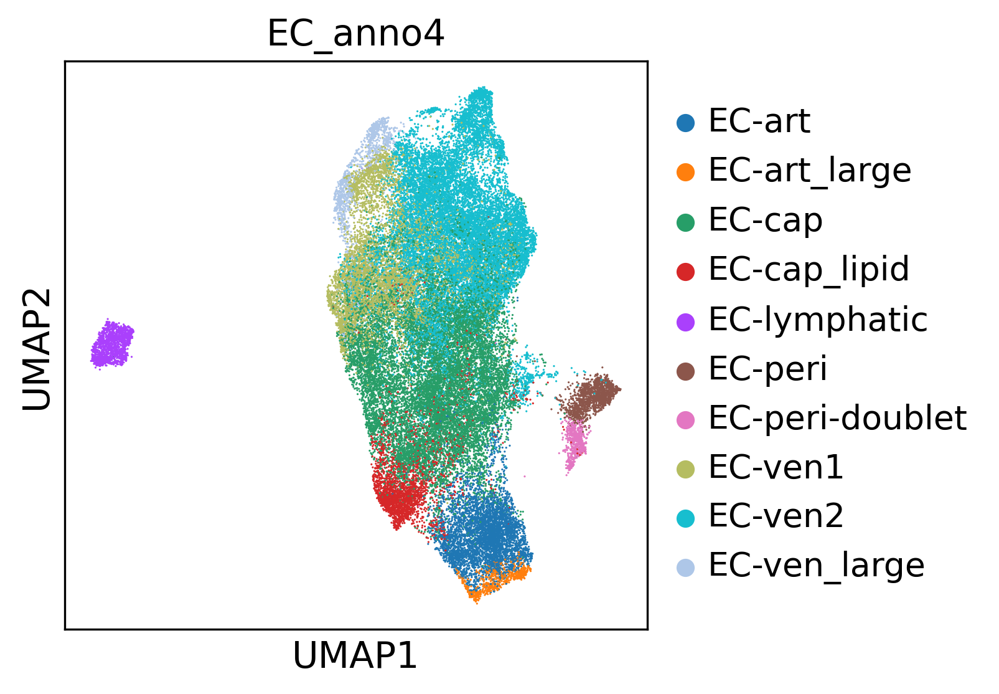

In [50]:
sc.pl.umap(adata_dbrm, color = 'EC_anno4')

In [51]:
adata_dbrm2 = adata_dbrm[adata_dbrm.obs['EC_anno4']!='EC-peri-doublet',].copy()

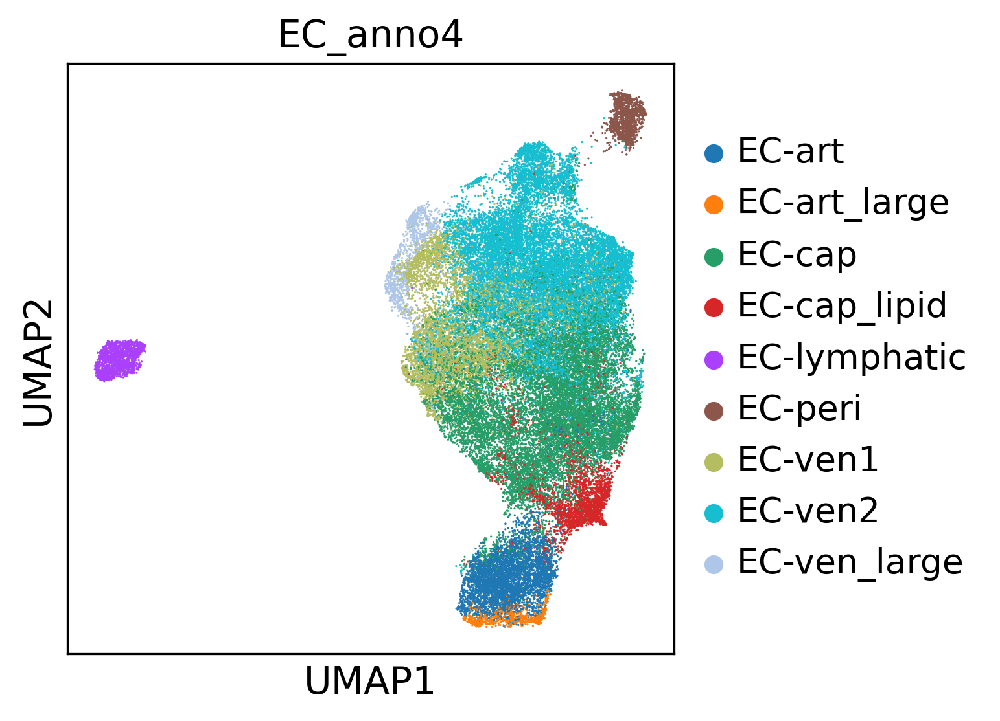

AnnData object with n_obs × n_vars = 50405 × 35530
    obs: 'barcode', 'sample', 'library', 'index', 'library_tcr_ab', 'library_tcr_gd', 'library_bcr', 'path_raw_gex', 'starsolo_version', 'path_cellbender_gex', 'path_cellranger_arc', 'donor', 'chemistry_simple', 'chemistry_detail', 'chemistry_orig', 'origin_institute', 'research_no', 'study', 'sort', 'sort_type', 'in_HTSA', 'public_data', 'type', 'cite', 'health_status', 'age_group', 'age_group2', 'age', 'age_num', 'age_unit', 'age_cont', 'sex', 'age_months', 'path_tcr_ab', 'path_tcr_gd', 'path_bcr', 'comment', 'n_counts', 'n_genes', 'percent_mito', 'percent_ribo', 'percent_hb', 'scrublet_score', 'predicted_doublet', 'taa_l5', 'taa_l4', 'taa_l3', 'taa_l2', 'taa_l1', 'taa_l0', 'doublet', 'stroma-anno1-coarse', 'stroma-anno1-granular', 'stroma-anno2-coarse', 'stroma-anno2-granular', 'doublet_verbose', 'EC_anno3', 'EC_anno', 'EC_annoR-leiden_r0.1', 'EC_annoR-leiden_r0.2', 'EC_annoR-leiden_r0.4', 'EC_annoR-leiden_r0.6', 'ctypist_vasc_predi

In [53]:
regen_embed(adata_dbrm2, 'EC_anno4')

In [71]:
annotations = pd.read_csv('/nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/data/objects/thyAgeing_vasc_v2_2layers_300epochs_batch-sample2025-01-25_anno_v2.csv', index_col = 0)

In [72]:
annotations['EC_anno4'] = adata_dbrm.obs.reindex(annotations.index)['EC_anno4'].copy()

In [73]:
annotations['EC_anno'] = annotations.apply(lambda x: x['EC_anno4'] if not pd.isnull(x['EC_anno4']) else
                                                     x['EC_anno'], axis = 1)

In [76]:
annotations.to_csv('/nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/data/objects/thyAgeing_vasc_v2_2layers_300epochs_batch-sample2025-02-03_anno_v3.csv')

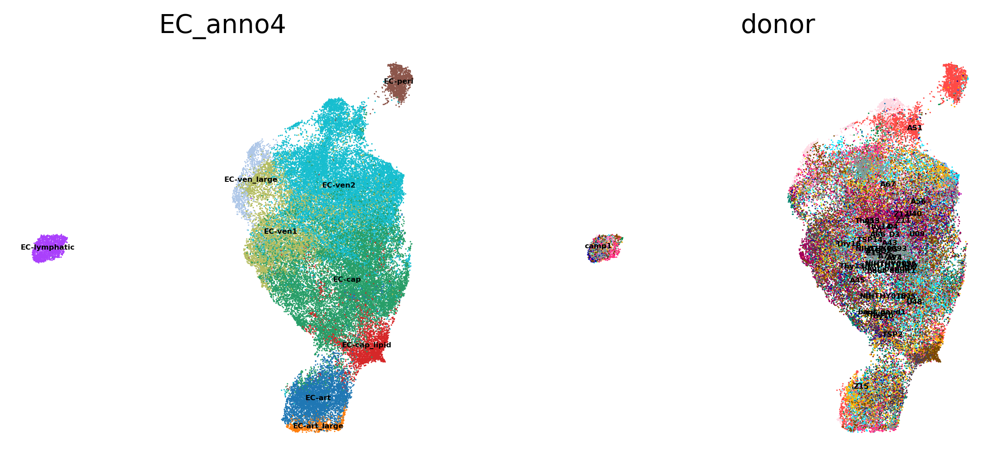

In [54]:
sc.pl.umap(adata_dbrm2, color = ['EC_anno4', 'donor'], legend_loc = 'on data', legend_fontsize = 4, frameon = False)

In [48]:
regen_embed(adata_dbrm2, 'EC_anno4')

Index(['barcode', 'sample', 'library', 'index', 'library_tcr_ab',
       'library_tcr_gd', 'library_bcr', 'path_raw_gex', 'starsolo_version',
       'path_cellbender_gex', 'path_cellranger_arc', 'donor',
       'chemistry_simple', 'chemistry_detail', 'chemistry_orig',
       'origin_institute', 'research_no', 'study', 'sort', 'sort_type',
       'in_HTSA', 'public_data', 'type', 'cite', 'health_status', 'age_group',
       'age_group2', 'age', 'age_num', 'age_unit', 'age_cont', 'sex',
       'age_months', 'path_tcr_ab', 'path_tcr_gd', 'path_bcr', 'comment',
       'n_counts', 'n_genes', 'percent_mito', 'percent_ribo', 'percent_hb',
       'scrublet_score', 'predicted_doublet', 'taa_l5', 'taa_l4', 'taa_l3',
       'taa_l2', 'taa_l1', 'taa_l0', 'doublet', 'stroma-anno1-coarse',
       'stroma-anno1-granular', 'stroma-anno2-coarse', 'stroma-anno2-granular',
       'doublet_verbose', 'EC_anno3', 'EC_anno', 'EC_annoR-leiden_r0.1',
       'EC_annoR-leiden_r0.2', 'EC_annoR-leiden_r0.4', 'EC_a

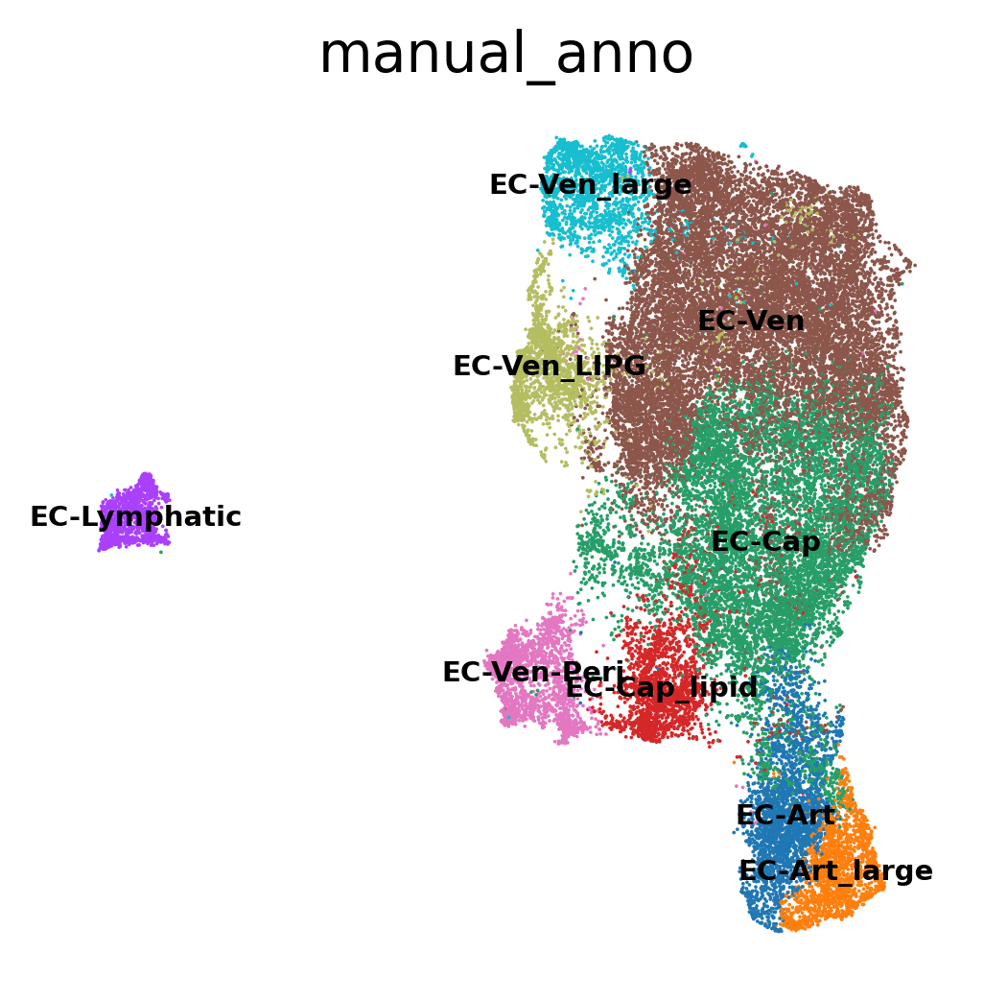

In [10]:
    scvi_run2['data'].write_h5ad(
        f'{data_path}/objects/thyAgeing_{scvi_embed_version}_{scvi_obj_version}.zarr',
        compression=hdf5plugin.FILTERS["zstd"],
        compression_opts=hdf5plugin.Zstd(clevel=5).filter_options,
    )
    scvi_run2['vae'].save(f'{model_path}/thyAgeing_{scvi_embed_version}_{scvi_obj_version}', save_anndata=True, overwrite=False)